# 01 EDA


In [1]:
from IPython.display import display
from pathlib import Path
import pandas as pd

# Locate the project from its root or a subdirectory such as notebooks.
project_dir = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "data" / "processed" / "customer_master.csv").is_file()),
    None,
)
if project_dir is None:
    raise FileNotFoundError(
        "Open this notebook from the project root or its notebooks folder. "
        "The project must contain data/processed/customer_master.csv."
    )
print("Project directory:", project_dir)


data_path = project_dir / "data" / "processed" / "customer_master.csv"

print("Data file:", data_path)
print("File exists:", data_path.exists())

Project directory: C:\Users\21129\Desktop\硕士申请材料\telecom-churn-retention-analysis
Data file: C:\Users\21129\Desktop\硕士申请材料\telecom-churn-retention-analysis\data\processed\customer_master.csv
File exists: True


In [2]:
df = pd.read_csv(
    data_path,
    dtype={"customer_id": "string"},
    na_values=["NULL"]
)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (7043, 21)


,customer_id,gender,senior_citizen,partner,dependents,tenure_months,phone_service,multiple_lines,internet_service,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
0,0002-ORFBO,Female,0,Yes,Yes,9,Yes,No,DSL,No,...,No,Yes,Yes,No,One year,Yes,Mailed check,65.6,593.30,No
1,0003-MKNFE,Male,0,No,No,9,Yes,Yes,DSL,No,...,No,No,No,Yes,Month-to-month,No,Mailed check,59.9,542.40,No
2,0004-TLHLJ,Male,0,No,No,4,Yes,No,Fiber optic,No,...,Yes,No,No,No,Month-to-month,Yes,Electronic check,73.9,280.85,Yes
3,0011-IGKFF,Male,1,Yes,No,13,Yes,No,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,98.0,1237.85,Yes
4,0013-EXCHZ,Female,1,Yes,No,3,Yes,No,Fiber optic,No,...,No,Yes,Yes,No,Month-to-month,Yes,Mailed check,83.9,267.40,Yes


In [3]:
data_check = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_count": df.isna().sum()
})

display(data_check)

print("Unique customers:", df["customer_id"].nunique())
print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())

print("\nChurn distribution:")
print(df["churn"].value_counts(dropna=False))

,data_type,missing_count
customer_id,string,0
gender,str,0
senior_citizen,int64,0
partner,str,0
dependents,str,0
tenure_months,int64,0
phone_service,str,0
multiple_lines,str,0
internet_service,str,0
online_security,str,0


Unique customers: 7043
Duplicate customer IDs: 0

Churn distribution:
churn
No     5174
Yes    1869
Name: count, dtype: int64


In [4]:
# Encode churn: churned = 1, not churned = 0.
df["churn_flag"] = df["churn"].map({"Yes": 1, "No": 0})

# Summarize customer counts and churn rates by contract.
contract_summary = (
    df.groupby("contract")
    .agg(
        customer_count=("customer_id", "size"),
        churn_rate=("churn_flag", "mean")
    )
    .reindex(["Month-to-month", "One year", "Two year"])
)

display(contract_summary)

,customer_count,churn_rate
contract,,
Month-to-month,3875,0.427097
One year,1473,0.112695
Two year,1695,0.028319


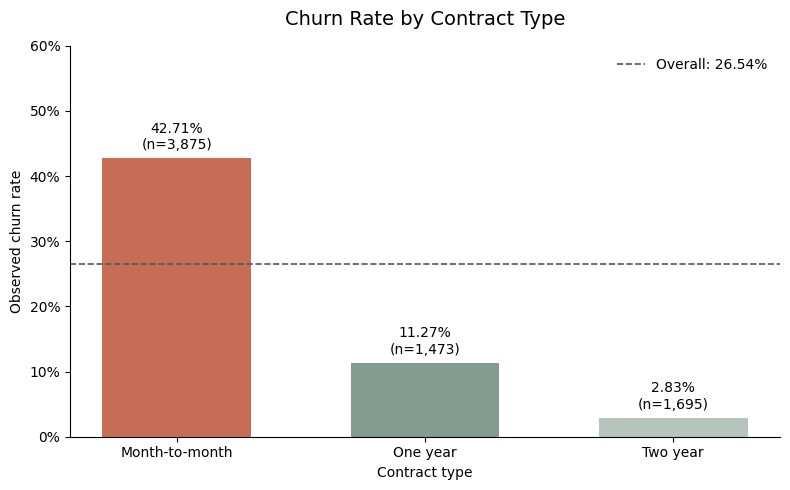

In [5]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

image_dir = project_dir / "images"
image_dir.mkdir(parents=True, exist_ok=True)

# Use the full-sample churn rate as a descriptive benchmark.
overall_churn_rate = df["churn_flag"].mean()

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    contract_summary.index,
    contract_summary["churn_rate"],
    color=["#C76D55", "#849B91", "#B5C4BD"],
    width=0.6
)

# Label bars with churn rates and customer counts.
for bar, rate, count in zip(
    bars,
    contract_summary["churn_rate"],
    contract_summary["customer_count"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        rate + 0.015,
        f"{rate:.2%}\n(n={count:,})",
        ha="center",
        fontsize=10
    )

# Add the overall churn rate reference line.
ax.axhline(
    overall_churn_rate,
    color="#555555",
    linestyle="--",
    linewidth=1.2,
    label=f"Overall: {overall_churn_rate:.2%}"
)

ax.set_title("Churn Rate by Contract Type", fontsize=14, pad=15)
ax.set_ylabel("Observed churn rate")
ax.set_xlabel("Contract type")
ax.set_ylim(0, 0.60)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(
    image_dir / "01_churn_by_contract.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Insight 1 — Churn differs substantially by contract type

- Month-to-month customers have an observed churn rate of 42.71%,
  compared with 11.27% for one-year and 2.83% for two-year contracts.
- The month-to-month group includes 3,875 customers and exceeds
  the overall churn rate by 16.17 percentage points.
- Business implication: investigate this large customer group further,
  combining tenure, service usage, and customer value.
- Limitation: this association does not prove that switching customers
  to longer contracts would reduce churn.

,customer_count,churn_rate
tenure_group,,
0–12 months,2186,0.474382
13–24 months,1024,0.287109
25–48 months,1594,0.203890
49+ months,2239,0.095132


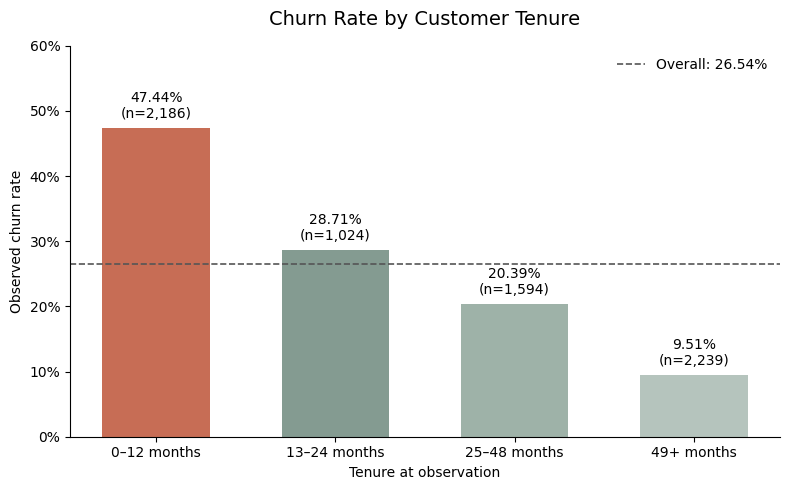

In [6]:
df["tenure_group"] = pd.cut(
    df["tenure_months"],
    bins=[-1, 12, 24, 48, float("inf")],
    labels=["0–12 months", "13–24 months", "25–48 months", "49+ months"],
    right=True
)

tenure_summary = (
    df.groupby("tenure_group", observed=True)
    .agg(
        customer_count=("customer_id", "size"),
        churn_rate=("churn_flag", "mean")
    )
)

display(tenure_summary)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    tenure_summary.index.astype(str),
    tenure_summary["churn_rate"],
    color=["#C76D55", "#849B91", "#9E B2A8".replace(" ", ""), "#B5C4BD"],
    width=0.6
)

for bar, rate, count in zip(
    bars,
    tenure_summary["churn_rate"],
    tenure_summary["customer_count"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        rate + 0.015,
        f"{rate:.2%}\n(n={count:,})",
        ha="center",
        fontsize=10
    )

ax.axhline(
    overall_churn_rate,
    color="#555555",
    linestyle="--",
    linewidth=1.2,
    label=f"Overall: {overall_churn_rate:.2%}"
)

ax.set_title("Churn Rate by Customer Tenure", fontsize=14, pad=15)
ax.set_xlabel("Tenure at observation")
ax.set_ylabel("Observed churn rate")
ax.set_ylim(0, 0.60)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)

fig.tight_layout()
fig.savefig(
    image_dir / "02_churn_by_tenure.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Insight 2 — Short-tenure customers have higher observed churn

- Customers with 0–12 months of tenure have a churn rate of 47.44%,
  compared with 9.51% for customers with 49+ months.
- Business implication: investigate onboarding, early billing,
  and service support as potential areas for retention experiments.
- Limitation: these are different customer groups in a snapshot.
  The chart does not track individual customers over time, and
  longer-tenure customers are a selected group who have remained.

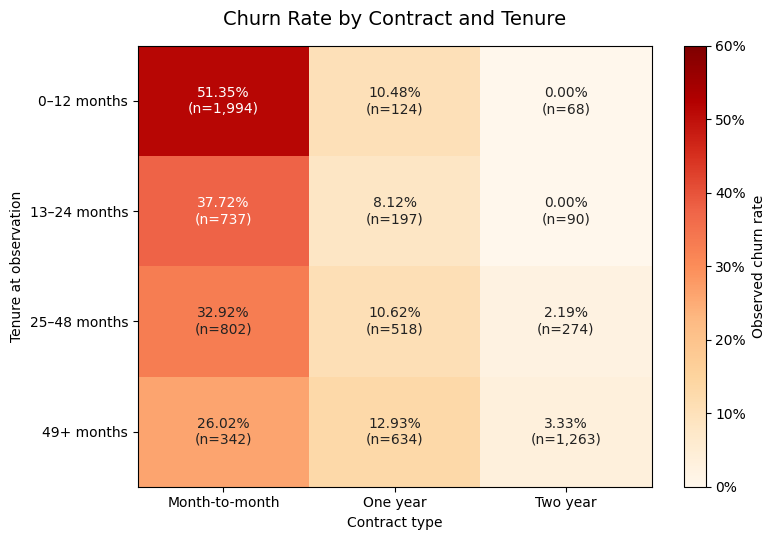

In [7]:
import numpy as np

# Calculate churn rates and sample sizes for each combination
contract_order = ["Month-to-month", "One year", "Two year"]
tenure_order = ["0–12 months", "13–24 months", "25–48 months", "49+ months"]

group_summary = (
    df.groupby(["tenure_group", "contract"], observed=True)
    .agg(
        customer_count=("customer_id", "size"),
        churn_rate=("churn_flag", "mean")
    )
    .reset_index()
)

rate_matrix = (
    group_summary.pivot(
        index="tenure_group",
        columns="contract",
        values="churn_rate"
    )
    .reindex(index=tenure_order, columns=contract_order)
)

count_matrix = (
    group_summary.pivot(
        index="tenure_group",
        columns="contract",
        values="customer_count"
    )
    .reindex(index=tenure_order, columns=contract_order)
)

# Draw the heatmap
fig, ax = plt.subplots(figsize=(8, 5.5))

heatmap = ax.imshow(
    rate_matrix.to_numpy(),
    cmap="OrRd",
    vmin=0,
    vmax=0.60,
    aspect="auto"
)

ax.set_xticks(np.arange(len(contract_order)))
ax.set_xticklabels(contract_order)
ax.set_yticks(np.arange(len(tenure_order)))
ax.set_yticklabels(tenure_order)

# Annotate each cell with its churn rate and sample size
for i in range(len(tenure_order)):
    for j in range(len(contract_order)):
        rate = rate_matrix.iloc[i, j]
        count = count_matrix.iloc[i, j]

        ax.text(
            j,
            i,
            f"{rate:.2%}\n(n={int(count):,})",
            ha="center",
            va="center",
            color="white" if rate >= 0.35 else "#222222",
            fontsize=10
        )

colorbar = fig.colorbar(heatmap, ax=ax)
colorbar.set_label("Observed churn rate")
colorbar.ax.yaxis.set_major_formatter(PercentFormatter(1.0))

ax.set_title("Churn Rate by Contract and Tenure", fontsize=14, pad=15)
ax.set_xlabel("Contract type")
ax.set_ylabel("Tenure at observation")

fig.tight_layout()
fig.savefig(
    image_dir / "03_churn_contract_tenure.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Insight 3 — Contract differences persist within tenure bands

- Month-to-month contracts have the highest observed churn rate
  within each tenure band.
- The 0–12 month, month-to-month segment has a churn rate of
  51.35% and contains 1,994 customers.
- Business implication: investigate this segment further and
  combine individual risk estimates with customer value.
- Limitation: broad tenure bands do not remove all confounding.
  Zero observed churn in small groups does not imply zero future risk.

monthly_charges               total_charges                  
                count median   mean         count   median     mean
churn                                                              
No               5174  64.43  61.27          5163  1683.60  2555.34
Yes              1869  79.65  74.44          1869   703.55  1531.80

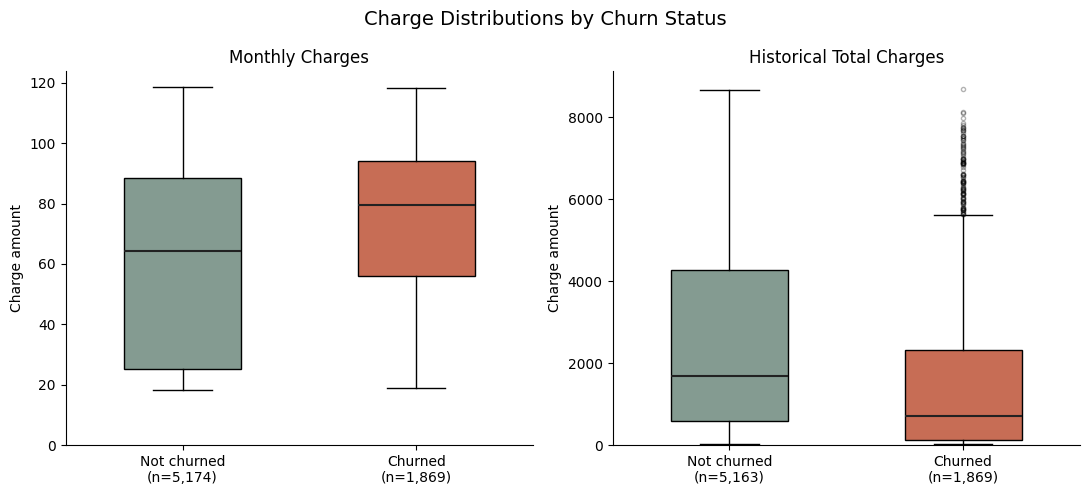

In [8]:
# Summarize charges by observed churn status
charge_summary = (
    df.groupby("churn")[["monthly_charges", "total_charges"]]
    .agg(["count", "median", "mean"])
    .round(2)
)

display(charge_summary)

# Compare charge distributions
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

features = [
    ("monthly_charges", "Monthly Charges"),
    ("total_charges", "Historical Total Charges")
]

status_order = ["No", "Yes"]
status_labels = ["Not churned", "Churned"]
colors = ["#849B91", "#C76D55"]

for ax, (column, title) in zip(axes, features):
    values = [
        df.loc[df["churn"] == status, column].dropna()
        for status in status_order
    ]

    boxplot = ax.boxplot(
        values,
        patch_artist=True,
        widths=0.5,
        medianprops={"color": "#222222", "linewidth": 1.5},
        flierprops={
            "marker": "o",
            "markersize": 3,
            "alpha": 0.3
        }
    )

    for box, color in zip(boxplot["boxes"], colors):
        box.set_facecolor(color)

    ax.set_xticks([1, 2])
    ax.set_xticklabels([
        f"{label}\n(n={len(group):,})"
        for label, group in zip(status_labels, values)
    ])

    ax.set_title(title)
    ax.set_ylabel("Charge amount")
    ax.set_ylim(bottom=0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("Charge Distributions by Churn Status", fontsize=14)
fig.tight_layout()

fig.savefig(
    image_dir / "04_charges_by_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Insight 4 — Higher monthly charges do not imply higher historical spending

- Churned customers have a higher median monthly charge:
  79.65 versus 64.43 for non-churned customers.
- Their median historical total charge is lower:
  703.55 versus 1,683.60.
- This pattern is consistent with the shorter tenure observed
  among many churned customers.
- Business implication: distinguish current billing level from
  historical spending when defining customer value.
- Limitation: these distributions overlap substantially.
  Neither charge measure alone identifies individual churn risk.
- Missing total charges were excluded only from the relevant
  summary and plot; customer records were retained.

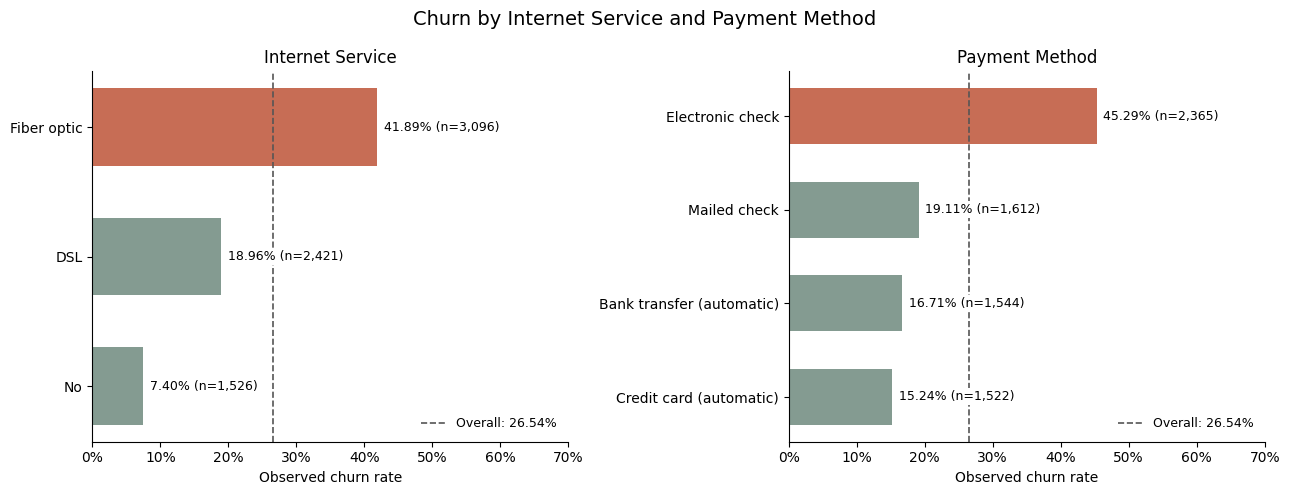

In [9]:
# Compare churn across service and payment categories
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_specs = [
    ("internet_service", "Internet Service"),
    ("payment_method", "Payment Method")
]

for ax, (column, title) in zip(axes, plot_specs):
    summary = (
        df.groupby(column)
        .agg(
            customer_count=("customer_id", "size"),
            churn_rate=("churn_flag", "mean")
        )
        .sort_values("churn_rate", ascending=False)
    )

    positions = np.arange(len(summary))

    colors = [
        "#C76D55" if rate > overall_churn_rate else "#849B91"
        for rate in summary["churn_rate"]
    ]

    ax.barh(
        positions,
        summary["churn_rate"],
        color=colors,
        height=0.6
    )

    ax.set_yticks(positions)
    ax.set_yticklabels(summary.index)
    ax.invert_yaxis()

    # Add the overall reference line
    ax.axvline(
        overall_churn_rate,
        color="#555555",
        linestyle="--",
        linewidth=1.2,
        label=f"Overall: {overall_churn_rate:.2%}",
        zorder=1
    )

    # Add labels with a white background
    for position, rate, count in zip(
        positions,
        summary["churn_rate"],
        summary["customer_count"]
    ):
        ax.text(
            rate + 0.01,
            position,
            f"{rate:.2%} (n={count:,})",
            va="center",
            fontsize=9,
            zorder=5,
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 1.0,
                "pad": 1.5
            }
        )

    ax.set_title(title)
    ax.set_xlabel("Observed churn rate")
    ax.set_xlim(0, 0.70)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False, loc="lower right", fontsize=9)

fig.suptitle(
    "Churn by Internet Service and Payment Method",
    fontsize=14
)
fig.tight_layout()

fig.savefig(
    image_dir / "05_churn_service_payment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Insight 5 — Fiber and electronic-check customers show higher churn

- Fiber optic customers have an observed churn rate of 41.89%,
  compared with the overall rate of 26.54%.
- Electronic-check customers have a churn rate of 45.29%,
  the highest among the payment categories.
- Business implication: investigate service and billing experiences
  in these groups and combine these attributes with other risk signals.
- Limitation: the panels describe overlapping customers.
  These associations do not establish that service type or payment
  method causes churn.

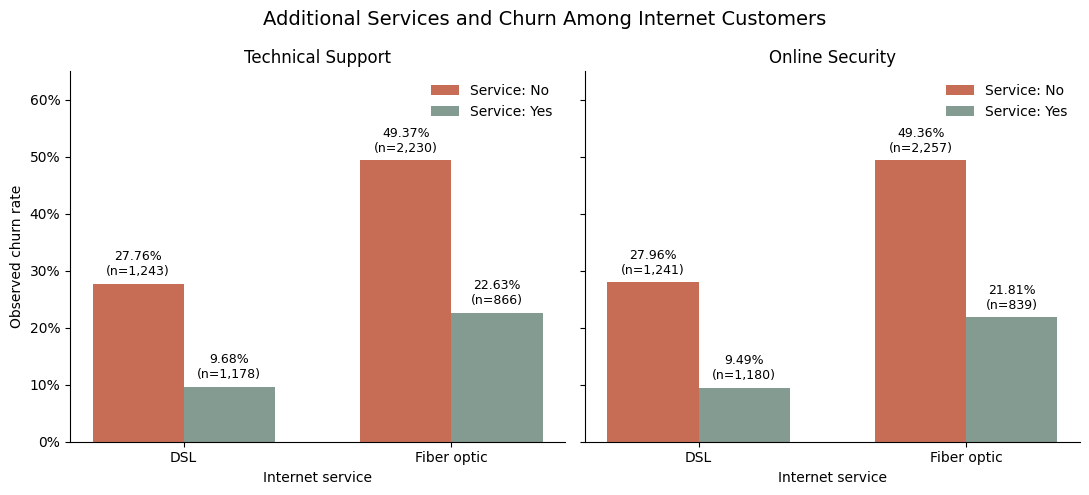

In [10]:
# Select customers with internet service
internet_customers = df.loc[
    df["internet_service"].isin(["DSL", "Fiber optic"])
].copy()

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

service_specs = [
    ("tech_support", "Technical Support"),
    ("online_security", "Online Security")
]

internet_order = ["DSL", "Fiber optic"]
positions = np.arange(len(internet_order))
bar_width = 0.34

for ax, (service, title) in zip(axes, service_specs):
    summary = (
        internet_customers
        .groupby(["internet_service", service])
        .agg(
            customer_count=("customer_id", "size"),
            churn_rate=("churn_flag", "mean")
        )
    )

    for status, offset, color in [
        ("No", -bar_width / 2, "#C76D55"),
        ("Yes", bar_width / 2, "#849B91")
    ]:
        subset = (
            summary.xs(status, level=service)
            .reindex(internet_order)
        )

        bars = ax.bar(
            positions + offset,
            subset["churn_rate"],
            width=bar_width,
            color=color,
            label=f"Service: {status}"
        )

        for bar, rate, count in zip(
            bars,
            subset["churn_rate"],
            subset["customer_count"]
        ):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                rate + 0.015,
                f"{rate:.2%}\n(n={count:,})",
                ha="center",
                fontsize=9
            )

    ax.set_xticks(positions)
    ax.set_xticklabels(internet_order)
    ax.set_title(title)
    ax.set_xlabel("Internet service")
    ax.set_ylim(0, 0.65)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False, loc="upper right")

axes[0].set_ylabel("Observed churn rate")

fig.suptitle(
    "Additional Services and Churn Among Internet Customers",
    fontsize=14
)
fig.tight_layout()

fig.savefig(
    image_dir / "06_churn_additional_services.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Insight 6 — Additional service subscriptions are associated with lower churn

- Within both DSL and fiber groups, customers with technical
  support or online security have lower observed churn rates.
- Among fiber customers, churn is 49.37% without technical support
  versus 22.63% with support.
- Business implication: investigate support needs and consider
  testing targeted service assistance.
- Limitation: subscription choices, contract types, and tenure
  may explain part of these differences. The gaps are not
  measured retention treatment effects.

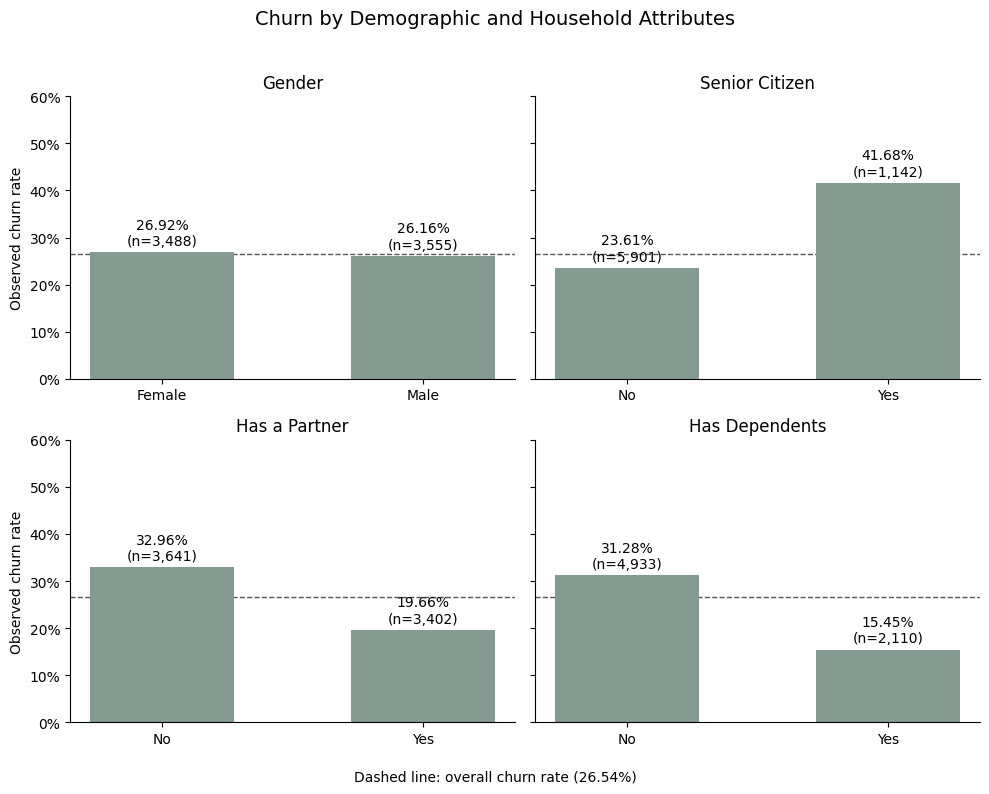

,attribute,category,customer_count,churn_rate
0,gender,Female,3488,0.269209
1,gender,Male,3555,0.261603
2,senior_citizen,0,5901,0.236062
3,senior_citizen,1,1142,0.416813
4,partner,No,3641,0.329580
5,partner,Yes,3402,0.196649
6,dependents,No,4933,0.312791
7,dependents,Yes,2110,0.154502


In [11]:
# Compare churn across demographic and household attributes
demographic_specs = [
    ("gender", "Gender", ["Female", "Male"], ["Female", "Male"]),
    ("senior_citizen", "Senior Citizen", [0, 1], ["No", "Yes"]),
    ("partner", "Has a Partner", ["No", "Yes"], ["No", "Yes"]),
    ("dependents", "Has Dependents", ["No", "Yes"], ["No", "Yes"])
]

fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharey=True)
summary_tables = []

for ax, (column, title, order, labels) in zip(
    axes.flat, demographic_specs
):
    summary = (
        df.groupby(column)
        .agg(
            customer_count=("customer_id", "size"),
            churn_rate=("churn_flag", "mean")
        )
        .reindex(order)
    )

    summary_tables.append(
        summary.reset_index()
        .rename(columns={column: "category"})
        .assign(attribute=column)
    )

    bars = ax.bar(
        labels,
        summary["churn_rate"],
        color="#849B91",
        width=0.55
    )

    for bar, rate, count in zip(
        bars,
        summary["churn_rate"],
        summary["customer_count"]
    ):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            rate + 0.015,
            f"{rate:.2%}\n(n={count:,})",
            ha="center",
            fontsize=10
        )

    ax.axhline(
        overall_churn_rate,
        color="#555555",
        linestyle="--",
        linewidth=1,
        zorder=0
    )

    ax.set_title(title)
    ax.set_ylim(0, 0.60)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0, 0].set_ylabel("Observed churn rate")
axes[1, 0].set_ylabel("Observed churn rate")

fig.suptitle("Churn by Demographic and Household Attributes", fontsize=14)
fig.text(
    0.5, 0.015,
    f"Dashed line: overall churn rate ({overall_churn_rate:.2%})",
    ha="center",
    fontsize=10,
    zorder=5,
    bbox={
        "facecolor": "white",
        "edgecolor": "none",
        "pad": 1.5
    }
)
fig.tight_layout(rect=[0, 0.04, 1, 0.96])

fig.savefig(
    image_dir / "07_churn_demographics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

demographic_summary = pd.concat(summary_tables, ignore_index=True)
display(
    demographic_summary[
        ["attribute", "category", "customer_count", "churn_rate"]
    ]
)

### Insight 7 — Household and demographic groups show different churn patterns

- Observed churn rates are similar across the recorded gender groups.
- Customers marked as senior citizens have higher observed churn.
- Customers with partners or dependents have lower observed churn.
- Business implication: investigate differences in service needs,
  contract choices, and customer experience across groups.
- Limitation: these are unadjusted associations, not causal effects
  or sufficient rules for allocating retention offers.

Non-churned customers: 5,174
Top-group customers: 1,035
Top-group monthly charge share: 33.67%


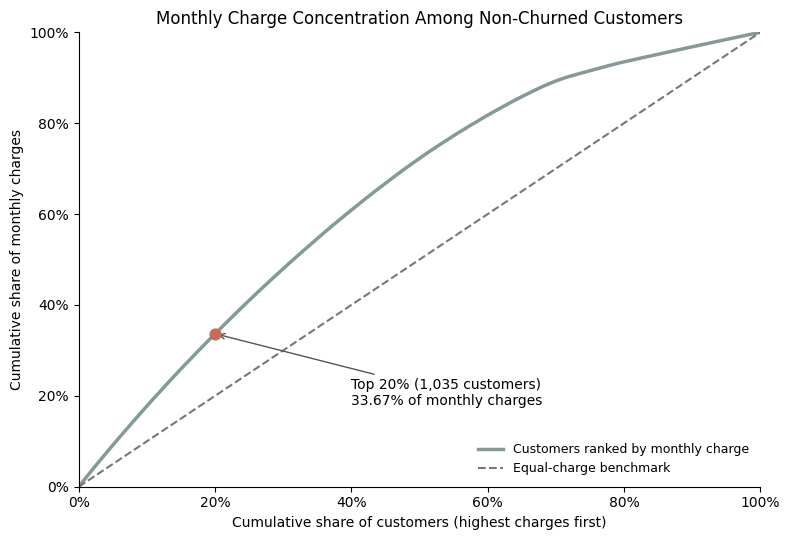

In [12]:
# Rank non-churned customers by monthly charges
active_ranked = (
    df.loc[df["churn"] == "No", ["customer_id", "monthly_charges"]]
    .sort_values(
        ["monthly_charges", "customer_id"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

customer_count = len(active_ranked)
total_monthly_charges = active_ranked["monthly_charges"].sum()

# Calculate cumulative customer and charge shares
customer_share = np.arange(1, customer_count + 1) / customer_count
charge_share = (
    active_ranked["monthly_charges"].cumsum()
    / total_monthly_charges
).to_numpy()

top_count = int(np.ceil(customer_count * 0.20))
top_customer_share = top_count / customer_count
top_charge_share = charge_share[top_count - 1]

print(f"Non-churned customers: {customer_count:,}")
print(f"Top-group customers: {top_count:,}")
print(f"Top-group monthly charge share: {top_charge_share:.2%}")

# Include the origin in the cumulative curve
x = np.r_[0, customer_share]
y = np.r_[0, charge_share]

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.plot(
    x, y,
    color="#849B91",
    linewidth=2.5,
    label="Customers ranked by monthly charge"
)

ax.plot(
    [0, 1], [0, 1],
    color="#777777",
    linestyle="--",
    label="Equal-charge benchmark"
)

ax.scatter(
    top_customer_share,
    top_charge_share,
    color="#C76D55",
    s=60,
    zorder=5
)

ax.annotate(
    f"Top 20% ({top_count:,} customers)\n"
    f"{top_charge_share:.2%} of monthly charges",
    xy=(top_customer_share, top_charge_share),
    xytext=(0.40, 0.18),
    arrowprops={"arrowstyle": "->", "color": "#555555"},
    fontsize=10
)

ax.set_title("Monthly Charge Concentration Among Non-Churned Customers")
ax.set_xlabel("Cumulative share of customers (highest charges first)")
ax.set_ylabel("Cumulative share of monthly charges")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, loc="lower right", fontsize=9)

fig.tight_layout()
fig.savefig(
    image_dir / "08_monthly_charge_concentration.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Insight 8 — Monthly charges show moderate concentration

- Among 5,174 non-churned customers, the top 1,035 by monthly
  charge contribute 33.67% of total monthly charges.
- The remaining customers contribute 66.33%.
- Business implication: prioritize using both churn risk and
  customer value rather than monthly charges alone.
- Limitation: monthly charges are a billing-value proxy,
  not profit, lifetime value, or recoverable revenue.

## EDA Summary

### Main Findings
1. Month-to-month customers have higher observed churn,
   including within each tenure band.
2. Short-tenure customers show higher observed churn.
3. Fiber and electronic-check customers show higher observed churn.
4. Technical support and online security subscriptions are
   associated with lower churn within internet-service groups.
5. Churned customers have higher median monthly charges but
   lower median historical total charges.
6. Gender differences are small descriptively, while senior
   and household groups show larger unadjusted differences.
7. High monthly charges and high churn risk are distinct concepts.

### Implications for Modeling
- Evaluate Logistic Regression and Random Forest.
- Exclude customer_id from model inputs.
- Use churn as the target; exclude both churn and its duplicate
  churn_flag from input features.
- Fit imputation, encoding, and scaling on training data only.
- Use validation data for model and threshold decisions.
- Evaluate the selected approach once on the held-out test set.
- Assess churn recall alongside precision, F1, ROC-AUC,
  and probability calibration.

### Limitations
- This is a sample-data, cross-sectional analysis.
- Associations do not establish causal retention effects.
- Full-sample SQL analysis and EDA preceded the modeling split;
  the later test set is therefore not fully untouched by exploration.
- Future-period validation would be needed before deployment.
- Retention effectiveness and costs are not observed in this dataset.